In [ ]:
# ============================================================
# Libraries
# ============================================================

import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import (
    AutoMinorLocator,
    FormatStrFormatter,
    MultipleLocator,
)

import numpy as np
import pandas as pd

from scipy.interpolate import Rbf
from scipy.optimize import curve_fit, minimize

from sklearn.ensemble import (
    ExtraTreesRegressor,
    RandomForestRegressor,
)
from sklearn.metrics import (
    make_scorer,
    r2_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    Normalizer,
    PolynomialFeatures,
    StandardScaler,
)

from xgboost import XGBRegressor
import xgboost as xgb

import plotly.graph_objects as go

In [180]:

df_train = pd.read_csv(Path("/home/ndong/Téléchargements/input/all_data_train.csv"))
df_train["charge_per_dose"] = df_train["charge"] / df_train["dose_delivered"]
df_train["charge_per_mu"] = df_train["charge"] / df_train["um_del"]

df_test = pd.read_csv(Path("/home/ndong/Téléchargements/input/all_data_test.csv"))
df_test["charge_per_dose"] = df_test["charge"] / df_test["dose_delivered"]
df_test["charge_per_mu"] = df_test["charge"] / df_test["um_del"]

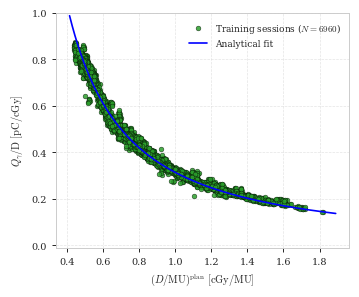

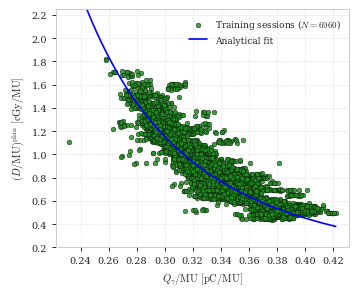

In [ ]:
# ============================================================
# Analytical model: inverse power-law
# ============================================================
%matplotlib inline

import matplotlib.pyplot as plt

def inverse_power_law(ratio, a, b):
    """(D/MU)plan from Qg/MU, by inversion of Qg/D = a (D/MU)^b."""
    return (np.asarray(ratio, float) / a) ** (1.0 / (b + 1.0))

def fit_power_law(ratio, dose_per_mu):
    """a and b minimising the mean relative error on D/MU after inversion.

    The search starts from the least-squares fit on Qg/D of the notebook.
    """
    def mean_relative_error(p):
        return np.mean(np.abs((inverse_power_law(ratio, *p) - dose_per_mu)
                              / dose_per_mu))
    res = minimize(mean_relative_error, (0.3178, -1.2732),
                   method="Nelder-Mead",
                   options=dict(xatol=1e-10, fatol=1e-12, maxiter=20000))
    return float(res.x[0]), float(res.x[1])

a, b = fit_power_law(df_train["charge_per_mu"], df_train["debit"])




# ============================================================
# Figure 1
# ============================================================

def frame(ax, ticks):
    for spine in ax.spines.values():
        spine.set_color("0.8")
        spine.set_linewidth(0.7)
    ax.tick_params(axis="both", length=3, width=0.7, color="0.15",
                   labelsize=ticks)


def save(fig, out_dir, name, formats):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    for ext in formats:
        fig.savefig(
            out_dir / f"{name}.{ext}",
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()
    plt.close(fig)

def draw_figure_1_a_b(train, a, b, out_dir, formats=("pdf", "png")):
    """Panels a and b on the training sessions, panel c on the test sessions."""
    plt.style.use("seaborn-v0_8-whitegrid")
    plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm"})

    # (a) Qg/D against (D/MU)plan, with the analytical fit
    x = train["debit"].values
    y = (train["charge"] / train["dose_delivered"]).values
    x_model = np.linspace(0.95 * x.min(), 1.04 * x.max(), 500)
    fig, ax = plt.subplots(figsize=(3.69, 3.08))
    ax.scatter(x, y, s=12, alpha=0.85, color="tab:green", edgecolor="black",
               linewidth=0.3, label=rf"Training sessions ($N={len(x)}$)")
    ax.plot(x_model, a * x_model ** b, color="blue", linewidth=1.2,
            label="Analytical fit")
    ax.set_ylabel(r"$Q_{\gamma}/\mathrm{D}\ \mathrm{[pC/cGy]}$", fontsize=7.5)
    ax.set_xlabel(r"$(D/\mathrm{MU})^{\mathrm{plan}}\ [\mathrm{cGy}/\mathrm{MU}]$",
                  fontsize=7.5)
    ax.set_ylim(-0.01, 1)
    frame(ax, 7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7, color="0.85")
    ax.legend(fontsize=6.5, frameon=False)
    fig.tight_layout()
    save(fig, out_dir, "Figure_1_a", formats)
    plt.show()

    # (b) The inverse relation, equation (3)
    x = train["charge_per_mu"].values
    y = train["debit"].values
    x_model = np.linspace(x.min(), x.max(), 1000)
    fig, ax = plt.subplots(figsize=(3.69, 3.08))
    ax.scatter(x, y, s=12, alpha=0.85, color="forestgreen", edgecolor="black",
               linewidth=0.3, label=rf"Training sessions ($N={len(x)}$)")
    ax.plot(x_model, inverse_power_law(x_model, a, b), color="blue",
            linewidth=1.2, label="Analytical fit")
    ax.set_xlabel(r"$Q_{\gamma}/\mathrm{MU}\ \mathrm{[pC/MU]}$", fontsize=7.5)
    ax.set_ylabel(r"$(D/\mathrm{MU})^{\mathrm{plan}}\ [\mathrm{cGy}/\mathrm{MU}]$",
                  fontsize=7.5)
    ax.xaxis.set_major_locator(MultipleLocator(0.02))
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    ax.set_ylim(0.2, 2.25)
    frame(ax, 7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7, color="0.85")
    ax.legend(fontsize=6.5, frameon=False)
    fig.tight_layout()
    save(fig, out_dir, "Figure_1_b", formats)
    plt.show()
    

draw_figure_1_a_b(
    df_train,
    a,
    b,
    out_dir="../results/figures_and_tables/",
    formats=("pdf", "png")
)

In [ ]:
# ============================================================
# RBF fit and 3D visualization on the training dataset
# ============================================================




# ============================================================
# Training data
# ============================================================

charge_train = df_train["charge"].values
mu_train = df_train["um_del"].values
debit_train = df_train["debit"].values


# ============================================================
# Fit RBF interpolator
# ============================================================

rbf = Rbf(
    charge_train,
    mu_train,
    debit_train,
    function="multiquadric",
    smooth=0.1
)

print("RBF interpolator fitted successfully.")


# ============================================================
# Create a grid over the training data range
# ============================================================

charge_grid = np.linspace(
    charge_train.min(),
    charge_train.max(),
    100
)

mu_grid = np.linspace(
    mu_train.min(),
    mu_train.max(),
    100
)

charge_mesh, mu_mesh = np.meshgrid(
    charge_grid,
    mu_grid
)


# ============================================================
# Evaluate the fitted RBF on the grid
# ============================================================

debit_mesh = rbf(
    charge_mesh,
    mu_mesh
)

# Enforce the physical constraint D/MU >= 0
debit_mesh = np.maximum(
    debit_mesh,
    0
)


# ============================================================
# 3D visualization
# ============================================================

fig = go.Figure()


# ------------------------------------------------------------
# RBF surface
# ------------------------------------------------------------

fig.add_trace(
    go.Surface(
        x=charge_mesh,
        y=mu_mesh,
        z=debit_mesh,
        colorscale="Viridis",
        opacity=0.85,
        showscale=True,

        colorbar=dict(
            title=dict(
                text="(D/MU)ᵖˡᵃⁿ [cGy/MU]",
                font=dict(size=22)
            ),
            tickfont=dict(size=16)
        ),

        name="RBF surface"
    )
)


# ------------------------------------------------------------
# Training data
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter3d(
        x=charge_train,
        y=mu_train,
        z=debit_train,
        mode="markers",
        marker=dict(
            size=2,
            color="black",
            opacity=0.35
        ),
        name=f"Training sessions (N={len(df_train)})"
    )
)


# ============================================================
# Axis labels and layout
# ============================================================

fig.update_layout(
    width=1200,
    height=900,


    scene=dict(

        xaxis=dict(
            title=dict(
                text="Qγ [pC]",
                font=dict(size=22)
            ),
            tickfont=dict(size=16)
        ),

        yaxis=dict(
            title=dict(
                text="MU",
                font=dict(size=22)
            ),
            tickfont=dict(size=16)
        ),

        zaxis=dict(
            title=dict(
                text="(D/MU)ᵖˡᵃⁿ [cGy/MU]",
                font=dict(size=22)
            ),
            tickfont=dict(size=16)
        )
    )
)


# ------------------------------------------------------------
# Save and display
# ------------------------------------------------------------

plt.tight_layout()

#plt.savefig(
#    "../results/figures_and_tables/Figure.png",
#    dpi=300,
#    bbox_inches="tight"
#)

fig.show()

RBF interpolator fitted successfully.


<Figure size 640x480 with 0 Axes>

In [199]:
# ============================================================
# Machine-learning configuration
# ============================================================

RANDOM_STATE = 42
POLY_DEGREE = 4
EPS = 1e-12


# ============================================================
# Target variable
# ============================================================

y = df_train["debit"].values


# ============================================================
# Selected configurations
# ============================================================
# Aligned with the evaluated feature / operation / model
# combinations.

selected_configs = [

    {
        "Features": r"$Q_{\gamma}$/MU, MU, $Q_{\gamma}$",
        "Variables": [
            "charge_per_mu",
            "um_del",
            "charge"
        ],
        "Operations": "Raw",
        "Model": "ET"
    },

    {
        "Features": r"$Q_{\gamma}$, MU",
        "Variables": [
            "charge",
            "um_del"
        ],
        "Operations": "Poly + Norm",
        "Model": "RF"
    },

    {
        "Features": r"$Q_{\gamma}$/MU, MU",
        "Variables": [
            "charge_per_mu",
            "um_del"
        ],
        "Operations": "Poly + Std",
        "Model": "RF"
    },

    {
        "Features": r"$Q_{\gamma}$/MU, $Q_{\gamma}$",
        "Variables": [
            "charge_per_mu",
            "charge"
        ],
        "Operations": "Raw",
        "Model": "ET"
    },

    {
        "Features": r"$Q_{\gamma}$/MU",
        "Variables": [
            "charge_per_mu"
        ],
        "Operations": "Raw",
        "Model": "XGB"
    },

    {
        "Features": r"$Q_{\gamma}$",
        "Variables": [
            "charge"
        ],
        "Operations": "Poly + Std",
        "Model": "XGB"
    },

    {
        "Features": "MU",
        "Variables": [
            "um_del"
        ],
        "Operations": "Poly + Norm",
        "Model": "XGB"
    }
]

In [200]:
# ============================================================
# Relative-error metrics
# ============================================================

def relative_errors(y_true, y_pred):
    return (
        100
        * (y_pred - y_true)
        / (y_true + EPS)
    )


def relative_mae(y_true, y_pred):
    return np.mean(
        np.abs(
            relative_errors(
                y_true,
                y_pred
            )
        )
    )


def relative_rmse(y_true, y_pred):
    return np.sqrt(
        np.mean(
            relative_errors(
                y_true,
                y_pred
            ) ** 2
        )
    )


def relative_std(y_true, y_pred):
    return np.std(
        relative_errors(
            y_true,
            y_pred
        )
    )

In [149]:
# ============================================================
# Utility functions for comparative clinical metrics
# ============================================================

def bootstrap_metrics(
    y_true,
    y_pred,
    n_boot=1000,
    seed=42
):
    """
    Compute bootstrap 95% confidence intervals for
    relative MAE, relative RMSE, and relative standard deviation.
    """

    rng = np.random.default_rng(
        seed
    )

    n = len(
        y_true
    )

    mae_boot = []
    rmse_boot = []
    std_boot = []

    for _ in range(n_boot):

        idx = rng.choice(
            n,
            size=n,
            replace=True
        )

        yt = y_true[idx]
        yp = y_pred[idx]

        err = (
            100
            * (yp - yt)
            / (yt + EPS)
        )

        mae_boot.append(
            np.mean(
                np.abs(err)
            )
        )

        rmse_boot.append(
            np.sqrt(
                np.mean(
                    err ** 2
                )
            )
        )

        std_boot.append(
            np.std(err)
        )

    return (
        np.percentile(
            mae_boot,
            [2.5, 97.5]
        ),
        np.percentile(
            rmse_boot,
            [2.5, 97.5]
        ),
        np.percentile(
            std_boot,
            [2.5, 97.5]
        )
    )


def build_summary_row(
    model,
    method,
    err,
    y_true,
    y_pred
):

    ci_mae, ci_rmse, ci_std = (
        bootstrap_metrics(
            y_true,
            y_pred
        )
    )

    return {
        "Model": model,
        "Method": method,
        "MAE (%)": np.mean(
            np.abs(err)
        ),
        "RMSE (%)": np.sqrt(
            np.mean(
                err ** 2
            )
        ),
        "STD (%)": np.std(err),
        "Median (%)": np.median(err),
        "Outside MAE ±3 (%)":
            100 * np.mean(
                np.abs(err) > 3
            ),
        "Outside MAE ±5 (%)":
            100 * np.mean(
                np.abs(err) > 5
            ),
        "Outside MAE ±10 (%)":
            100 * np.mean(
                np.abs(err) > 10
            ),
        "MAE 95% CI":
            f"[{ci_mae[0]:.2f}, "
            f"{ci_mae[1]:.2f}]",
        "RMSE 95% CI":
            f"[{ci_rmse[0]:.2f}, "
            f"{ci_rmse[1]:.2f}]",
        "STD 95% CI":
            f"[{ci_std[0]:.2f}, "
            f"{ci_std[1]:.2f}]"
    }

In [201]:
# ============================================================
# Scoring
# ============================================================

scoring = {
    "R2": "r2",
    "MAE_rel": make_scorer(
        relative_mae,
        greater_is_better=False
    ),
    "RMSE_rel": make_scorer(
        relative_rmse,
        greater_is_better=False
    ),
    "STD_rel": make_scorer(
        relative_std,
        greater_is_better=False
    )
}


# ============================================================
# Cross-validation
# ============================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [202]:
# ============================================================
# Transformations
# ============================================================

transformations = {

    "Raw": [],

    "StandardScaler": [
        ("std", StandardScaler())
    ],

    "MinMaxScaler": [
        ("minmax", MinMaxScaler())
    ],

    "Normalizer": [
        ("norm", Normalizer())
    ],

    "Poly": [
        (
            "poly",
            PolynomialFeatures(
                POLY_DEGREE,
                include_bias=False
            )
        )
    ],

    "Poly + Std": [
        (
            "poly",
            PolynomialFeatures(
                POLY_DEGREE,
                include_bias=False
            )
        ),
        (
            "std",
            StandardScaler()
        )
    ],

    "Poly + MinMax": [
        (
            "poly",
            PolynomialFeatures(
                POLY_DEGREE,
                include_bias=False
            )
        ),
        (
            "minmax",
            MinMaxScaler()
        )
    ],

    "Poly + Norm": [
        (
            "poly",
            PolynomialFeatures(
                POLY_DEGREE,
                include_bias=False
            )
        ),
        (
            "norm",
            Normalizer()
        )
    ]
}

In [203]:
# ============================================================
# Machine-learning models
# ============================================================

models = {

    "RF": RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "ET": ExtraTreesRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGB": xgb.XGBRegressor(
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

In [204]:
# ============================================================
# Hyperparameter grids
# ============================================================

param_grids = {

    "RF": {
        "model__n_estimators": [
            100,
            200,
            500
        ],
        "model__max_depth": [
            None,
            5,
            10,
            20
        ],
        "model__min_samples_split": [
            2,
            5,
            10
        ],
        "model__min_samples_leaf": [
            1,
            2,
            5
        ]
    },

    "ET": {
        "model__n_estimators": [
            100,
            200,
            500
        ],
        "model__max_depth": [
            None,
            5,
            10,
            20
        ],
        "model__min_samples_split": [
            2,
            5,
            10
        ],
        "model__min_samples_leaf": [
            1,
            2,
            5
        ]
    },

    "XGB": {
        "model__n_estimators": [
            100,
            200,
            500
        ],
        "model__max_depth": [
            2,
            4,
            6
        ],
        "model__learning_rate": [
            0.01,
            0.05,
            0.1
        ],
        "model__subsample": [
            0.8,
            1.0
        ],
        "model__colsample_bytree": [
            0.8,
            1.0
        ]
    }
}

In [154]:
# ============================================================
# Grid search and cross-validation
# ============================================================

results = []
best_estimators = {}


for cfg in selected_configs:

    print(
        f"\n===== {cfg['Features']} ====="
    )

    X = df_train[
        cfg["Variables"]
    ]

    pipe = Pipeline(
        transformations[
            cfg["Operations"]
        ]
        + [
            (
                "model",
                models[
                    cfg["Model"]
                ]
            )
        ]
    )

    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[
            cfg["Model"]
        ],
        scoring="r2",
        cv=cv,
        n_jobs=-1
    )

    search.fit(
        X,
        y
    )

    best_pipe = search.best_estimator_

    best_estimators[
        cfg["Features"]
    ] = {
        "pipeline": best_pipe,
        "variables": cfg["Variables"]
    }

    cv_results = cross_validate(
        best_pipe,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append(
        {
            "Features": cfg["Features"],
            "Operations": cfg["Operations"],
            "Model": cfg["Model"],
            "Best_Params": search.best_params_,
            "CV_R2": np.mean(
                cv_results["test_R2"]
            ),
            "CV_R2_STD": np.std(
                cv_results["test_R2"]
            ),
            "MAE_percent": np.mean(
                -cv_results["test_MAE_rel"]
            ),
            "RMSE_percent": np.mean(
                -cv_results["test_RMSE_rel"]
            ),
            "STD_percent": np.mean(
                -cv_results["test_STD_rel"]
            )
        }
    )


===== $Q_{\gamma}$/MU, MU, $Q_{\gamma}$ =====

===== $Q_{\gamma}$, MU =====

===== $Q_{\gamma}$/MU, MU =====

===== $Q_{\gamma}$/MU, $Q_{\gamma}$ =====

===== $Q_{\gamma}$/MU =====

===== $Q_{\gamma}$ =====

===== MU =====


In [205]:
# ============================================================
# Final results after grid search
# ============================================================

results_df = pd.DataFrame(
    results
)

results_df = results_df.sort_values(
    "MAE_percent",
    ascending=True
)

print(
    "\n\n===== RESULTS AFTER GRID SEARCH "
    "(TRAIN, CV) ====="
)

display(
    results_df
)


# ============================================================
# Global model selection
# ============================================================

best_row = results_df.iloc[2]

best_features_name = best_row[
    "Features"
]

final_pipeline = best_estimators[
    best_features_name
]["pipeline"]

final_variables = best_estimators[
    best_features_name
]["variables"]

print(
    f"\nFinal selected model: "
    f"{best_features_name} | "
    f"{best_row['Operations']} | "
    f"{best_row['Model']}"
)



===== RESULTS AFTER GRID SEARCH (TRAIN, CV) =====


,Features,Operations,Model,Best_Params,CV_R2,CV_R2_STD,MAE_percent,RMSE_percent,STD_percent
0,"$Q_{\gamma}$/MU, MU, $Q_{\gamma}$",Raw,ET,"{'model__max_depth': 20, 'model__min_samples_l...",0.967935,0.006443,2.394277,6.426627,6.412314
2,"$Q_{\gamma}$/MU, MU",Poly + Std,RF,"{'model__max_depth': 20, 'model__min_samples_l...",0.963914,0.006299,2.469887,6.684950,6.669182
1,"$Q_{\gamma}$, MU",Poly + Norm,RF,"{'model__max_depth': 20, 'model__min_samples_l...",0.964063,0.006352,2.525612,6.688629,6.675224
3,"$Q_{\gamma}$/MU, $Q_{\gamma}$",Raw,ET,"{'model__max_depth': 20, 'model__min_samples_l...",0.965692,0.006167,2.610200,6.625969,6.609184
4,$Q_{\gamma}$/MU,Raw,XGB,"{'model__colsample_bytree': 0.8, 'model__learn...",0.872106,0.009423,8.650262,11.706236,11.614954
5,$Q_{\gamma}$,Poly + Std,XGB,"{'model__colsample_bytree': 0.8, 'model__learn...",0.511320,0.018779,18.341658,27.969889,27.346638
6,MU,Poly + Norm,XGB,"{'model__colsample_bytree': 1.0, 'model__learn...",0.411451,0.024564,19.465126,31.173895,30.309168



Final selected model: $Q_{\gamma}$, MU | Poly + Norm | RF


In [206]:
# ============================================================
# Final retraining on the complete training set
# ============================================================

X_train_final = df_train[
    final_variables
]

final_pipeline.fit(
    X_train_final,
    y
)

,steps,"[('poly', ...), ('norm', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,degree,4
,interaction_only,False
,include_bias,False
,order,'C'
,norm,'l2'
,copy,True
,n_estimators,200


In [207]:
# ============================================================
# Prepare the independent test set
# ============================================================

if (
    "charge_per_mu" in final_variables
    and "charge_per_mu" not in df_test.columns
):
    df_test = df_test.copy()

    df_test["charge_per_mu"] = (
        df_test["charge"]
        / (df_test["um_del"] + EPS)
    )

X_test_final = df_test[
    final_variables
]

In [208]:

def load_split(data_dir):
    """Training sessions and the three test sets of the patient-level split."""
    data_dir = Path(data_dir)
    train = pd.read_csv(data_dir / "all_data_train.csv")
    train["charge_per_mu"] = train["charge"] / train["um_del"]
    tests = {}
    for name, file in TEST_FILES.items():
        df = pd.read_csv(data_dir / file)
        df["charge_per_mu"] = df["charge"] / (df["um_del"] + EPS)
        tests[name] = df
    return train, tests

# ============================================================
# Predictions on the independent test set
# ============================================================

y_pred_test = final_pipeline.predict(
    X_test_final
)

predictions_df = df_test.copy()


model_names = {
    "RF": "RandomForest",
    "ET": "ExtraTrees",
    "XGB": "XGBoost"
}


best_ml_name = model_names.get(
    best_row["Model"],
    best_row["Model"]
)


predictions_df[
    f"debit_predicted_{best_ml_name}"
] = y_pred_test


print(
    "\n===== PREDICTIONS ON INDEPENDENT TEST SET ====="
)

display(
    predictions_df.head()
)


===== PREDICTIONS ON INDEPENDENT TEST SET =====


,debit,dose_delivered,um_del,dose_delivered.1,charge,charge_per_dose,charge_per_mu,debit_predicted_RandomForest
0,0.527264,1300.234050,2466.0,1300.234050,966.9999,0.743712,0.392133,0.526721
1,0.663316,1300.099967,1960.0,1300.099967,680.3000,0.523267,0.347092,0.663717
2,0.506431,135.217165,267.0,135.217165,105.3300,0.778969,0.394494,0.530111
3,0.547386,1300.042719,2375.0,1300.042719,942.9000,0.725284,0.397011,0.547087
4,0.682987,1299.042207,1902.0,1299.042207,637.0000,0.490361,0.334911,0.684788


In [209]:
# ============================================================
# Independent test-set metrics
# ============================================================

if "debit" in df_test.columns:

    y_test_true = (
        df_test["debit"].values
    )

    test_r2 = r2_score(
        y_test_true,
        y_pred_test
    )

    test_mae = relative_mae(
        y_test_true,
        y_pred_test
    )

    test_rmse = relative_rmse(
        y_test_true,
        y_pred_test
    )

    test_std = relative_std(
        y_test_true,
        y_pred_test
    )


    print(
        "\n===== PERFORMANCE ON "
        "INDEPENDENT TEST SET ====="
    )

    print(
        f"R²    = {test_r2:.4f}"
    )

    print(
        f"MAE%  = {test_mae:.2f}%"
    )

    print(
        f"RMSE% = {test_rmse:.2f}%"
    )

    print(
        f"STD%  = {test_std:.2f}%"
    )

else:

    print(
        "\nColumn 'debit' is not available "
        "in the test set. Metrics cannot be "
        "computed; only predictions are available."
    )


===== PERFORMANCE ON INDEPENDENT TEST SET =====
R²    = 0.9406
MAE%  = 3.56%
RMSE% = 9.01%
STD%  = 8.98%


In [224]:
# ============================================================
# Comparative analysis on the independent test set
# Best ML models + RBF + analytical model
# ============================================================



if "debit" in df_test.columns:

    relative_errors_dict = {}

    labels = []

    summary = []


    model_names = {
        "RF": "Random Forest",
        "ET": "Extra Trees",
        "XGB": "XGBoost"
    }


    # --------------------------------------------------------
    # Machine-learning models
    # --------------------------------------------------------

    for cfg in selected_configs:

        pipe = best_estimators[
            cfg["Features"]
        ]["pipeline"]

        variables = best_estimators[
            cfg["Features"]
        ]["variables"]


        X_test = df_test[
            variables
        ].copy()

        y_true = (
            df_test["debit"].values
        )


        mask = (
            np.isfinite(X_test).all(axis=1)
            & np.isfinite(y_true)
        )


        X_test = X_test.loc[
            mask
        ]

        y_true = y_true[
            mask
        ]


        y_pred = pipe.predict(
            X_test
        )


        err = (
            100
            * (y_pred - y_true)
            / (y_true + EPS)
        )


        relative_errors_dict[
            cfg["Features"]
        ] = err


        labels.append(
            f"{cfg['Features']}\n"
            f"{model_names.get(cfg['Model'], cfg['Model'])}\n"
            f"{cfg['Operations']}"
        )


        summary.append(
            build_summary_row(
                cfg["Features"],
                cfg["Model"],
                err,
                y_true,
                y_pred
            )
        )


    # --------------------------------------------------------
    # RBF interpolator
    # --------------------------------------------------------

    rbf = Rbf(
        df_train["charge"].values,
        df_train["um_del"].values,
        df_train["debit"].values,
        function="multiquadric",
        smooth=0.1
    )


    z_true = (
        df_test["debit"].values
    )


    z_pred = rbf(
        df_test["charge"].values,
        df_test["um_del"].values
    )


    predictions_df[
        "debit_predicted_RBF"
    ] = z_pred


    err = (
        100
        * (z_pred - z_true)
        / (z_true + EPS)
    )

    err = err[
        np.isfinite(err)
    ]


    relative_errors_dict[
        "RBF"
    ] = err


    labels.append(
        r"$Q_{\gamma}$, MU"
        "\n"
        "RBF Interpolator"
    )


    summary.append(
        build_summary_row(
            "RBF",
            "Interpolator",
            err,
            z_true,
            z_pred
        )
    )


    # --------------------------------------------------------
    # Analytical model
    # --------------------------------------------------------

    a_analytic = a
    b_analytic = b


    x = (
        df_test["charge_per_mu"].values
    )

    y_true = (
        df_test["debit"].values
    )


    y_pred = (
        x / a_analytic
    ) ** (
        1 / (1 + b_analytic)
    )


    predictions_df[
        "debit_predicted_Analytical"
    ] = y_pred


    err = (
        100
        * (y_pred - y_true)
        / (y_true + EPS)
    )

    err = err[
        np.isfinite(err)
    ]


    relative_errors_dict[
        "Analytical"
    ] = err


    labels.append(
        r"$Q_{\gamma}$/MU"
        "\n"
        "Analytical Model"
    )


    summary.append(
        build_summary_row(
            "Analytical",
            "Analytical",
            err,
            y_true,
            y_pred
        )
    )

In [225]:
# ============================================================
# Summary tables and export
# ============================================================

summary_df = pd.DataFrame(
    summary
)


print(
    "\n===== RELATIVE ERROR SUMMARY ====="
)

display(
    summary_df
)


# Save summary and predictions
#summary_df.to_csv(
#    "../results/predictions/Summary_models.csv",
#    index=False
#)

#predictions_df.to_csv(
#    "../results/predictions/Predictions_models.csv",
#    index=False
#)


===== RELATIVE ERROR SUMMARY =====


,Model,Method,MAE (%),RMSE (%),STD (%),Median (%),Outside MAE ±3 (%),Outside MAE ±5 (%),Outside MAE ±10 (%),MAE 95% CI,RMSE 95% CI,STD 95% CI
0,"$Q_{\gamma}$/MU, MU, $Q_{\gamma}$",ET,3.573157,8.861694,8.835071,-0.014303,25.810119,19.727118,12.336555,"[3.21, 3.96]","[7.40, 10.55]","[7.37, 10.50]"
1,"$Q_{\gamma}$, MU",RF,3.556151,9.005009,8.983441,-0.028593,25.071063,19.613417,11.881751,"[3.18, 3.95]","[7.42, 10.69]","[7.41, 10.65]"
2,"$Q_{\gamma}$/MU, MU",RF,3.626165,9.085804,9.052365,-0.008557,25.753269,19.840819,12.279704,"[3.25, 4.02]","[7.62, 10.75]","[7.59, 10.70]"
3,"$Q_{\gamma}$/MU, $Q_{\gamma}$",ET,3.587636,8.702053,8.666341,0.006849,26.492325,20.011370,12.279704,"[3.24, 3.96]","[7.21, 10.39]","[7.17, 10.33]"
4,$Q_{\gamma}$/MU,XGB,9.312882,13.657231,13.397833,2.525335,78.681069,61.796475,33.712337,"[8.85, 9.82]","[12.23, 15.25]","[12.00, 14.89]"
5,$Q_{\gamma}$,XGB,20.649399,32.364414,31.084792,0.351182,69.982945,62.592382,53.155202,"[19.55, 21.91]","[30.51, 34.31]","[29.42, 32.83]"
6,MU,XGB,22.313866,36.143848,34.520703,0.211455,59.465605,54.803866,47.868107,"[21.08, 23.80]","[34.32, 38.20]","[32.94, 36.27]"
7,RBF,Interpolator,3.840293,9.125662,9.115908,-0.017213,27.117681,20.068221,13.132462,"[3.47, 4.24]","[7.76, 10.78]","[7.75, 10.76]"
8,Analytical,Analytical,9.573811,13.696222,13.687604,-0.338918,77.828312,65.264355,36.100057,"[9.14, 10.04]","[12.45, 15.05]","[12.44, 15.02]"


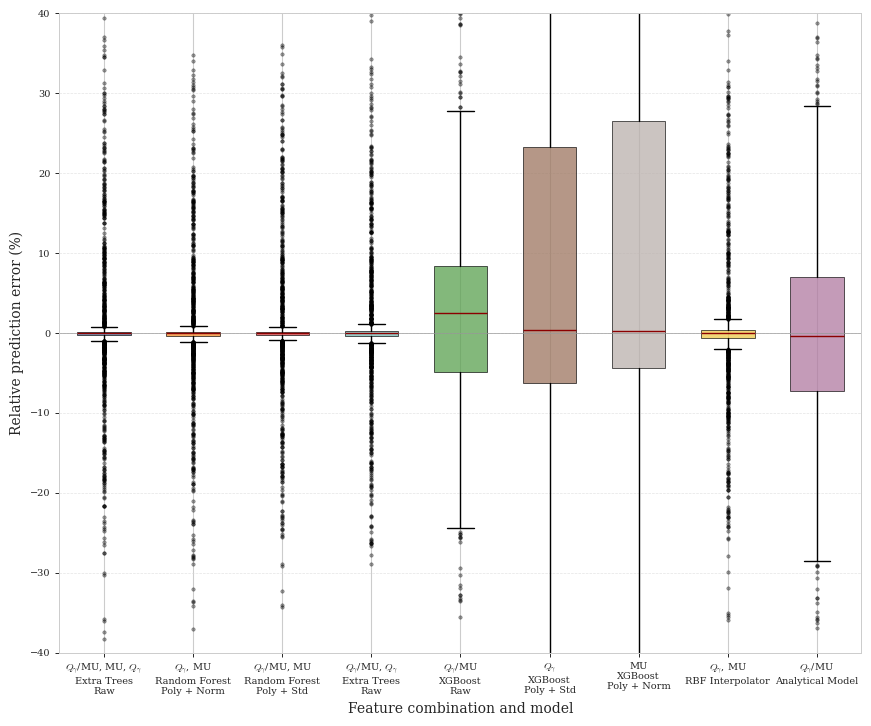

In [ ]:
################## synthèse / comparaison finale ######################


# ============================================================
# Configuration
# ============================================================

RANDOM_STATE = 42
POLY_DEGREE = 4
EPS = 1e-12

# An alteration is declared when the predicted dose per monitor unit moves
# by more than this level (%) from the nominal deliveries of the session.
ALARM_LEVEL = 10.0

# The input and model combinations of the notebook, in its order.
CONFIGS = [
    dict(key="Qg/MU, MU, Qg", label=r"$Q_{\gamma}$/MU, MU, $Q_{\gamma}$",
         variables=["charge_per_mu", "um_del", "charge"],
         operations="Raw", model="ET",
         params=dict(max_depth=20, min_samples_leaf=1, min_samples_split=5,
                     n_estimators=200)),
    dict(key="Qg, MU", label=r"$Q_{\gamma}$, MU",
         variables=["charge", "um_del"],
         operations="Poly + Norm", model="RF",
         params=dict(max_depth=20, min_samples_leaf=2, min_samples_split=2,
                     n_estimators=200)),
    dict(key="Qg/MU, MU", label=r"$Q_{\gamma}$/MU, MU",
         variables=["charge_per_mu", "um_del"],
         operations="Poly + Std", model="RF",
         params=dict(max_depth=20, min_samples_leaf=1, min_samples_split=2,
                     n_estimators=200)),
    dict(key="Qg/MU, Qg", label=r"$Q_{\gamma}$/MU, $Q_{\gamma}$",
         variables=["charge_per_mu", "charge"],
         operations="Raw", model="ET",
         params=dict(max_depth=20, min_samples_leaf=1, min_samples_split=5,
                     n_estimators=500)),
    dict(key="Qg/MU", label=r"$Q_{\gamma}$/MU",
         variables=["charge_per_mu"],
         operations="Raw", model="XGB",
         params=dict(colsample_bytree=1.0, learning_rate=0.01, max_depth=2,
                     n_estimators=500, subsample=0.8)),
    dict(key="Qg", label=r"$Q_{\gamma}$",
         variables=["charge"],
         operations="Poly + Std", model="XGB",
         params=dict(colsample_bytree=0.8, learning_rate=0.1, max_depth=2,
                     n_estimators=200, subsample=1.0)),
    dict(key="MU", label="MU",
         variables=["um_del"],
         operations="Poly + Norm", model="XGB",
         params=dict(colsample_bytree=1.0, learning_rate=0.01, max_depth=4,
                     n_estimators=500, subsample=0.8)),
]
CONFIG = {cfg["key"]: cfg for cfg in CONFIGS}
KEYS = [cfg["key"] for cfg in CONFIGS] + ["RBF", "Analytical"]
MODEL_NAMES = {"RF": "Random Forest", "ET": "Extra Trees", "XGB": "XGBoost"}

TEST_FILES = {"all": "all_data_test.csv",
              "complete": "input_complet_test.csv",
              "interrupted": "input_partial_test.csv"}

# Row order of the printed tables, as in the supplement.
ORDER_S5 = ["Analytical", "RBF", "Qg", "MU", "Qg/MU", "Qg, MU", "Qg/MU, MU",
            "Qg/MU, Qg", "Qg/MU, MU, Qg"]
ORDER_S12 = ["Analytical", "RBF", "Qg/MU, MU, Qg", "Qg, MU", "Qg/MU, MU",
             "Qg/MU, Qg", "Qg/MU", "Qg", "MU"]




# ============================================================
# Data
# ============================================================

def load_split(data_dir):
    """Training sessions and the three test sets of the patient-level split."""
    data_dir = Path(data_dir)
    train = pd.read_csv(data_dir / "all_data_train.csv")
    train["charge_per_mu"] = train["charge"] / train["um_del"]
    tests = {}
    for name, file in TEST_FILES.items():
        df = pd.read_csv(data_dir / file)
        df["charge_per_mu"] = df["charge"] / (df["um_del"] + EPS)
        tests[name] = df
    return train, tests




# ============================================================
# Analytical models
# ============================================================

def inverse_power_law(ratio, a, b):
    """(D/MU)plan from Qg/MU, by inversion of Qg/D = a (D/MU)^b."""
    return (np.asarray(ratio, float) / a) ** (1.0 / (b + 1.0))


def fit_power_law(ratio, dose_per_mu):
    """a and b minimising the mean relative error on D/MU after inversion.

    The search starts from the least-squares fit on Qg/D of the notebook.
    """
    def mean_relative_error(p):
        return np.mean(np.abs((inverse_power_law(ratio, *p) - dose_per_mu)
                              / dose_per_mu))
    res = minimize(mean_relative_error, (0.3178, -1.2732),
                   method="Nelder-Mead",
                   options=dict(xatol=1e-10, fatol=1e-12, maxiter=20000))
    return float(res.x[0]), float(res.x[1])





# ============================================================
# Machine-learning models
# ============================================================

def make_pipeline(cfg):
    poly = ("poly", PolynomialFeatures(POLY_DEGREE, include_bias=False))
    steps = {"Raw": [],
             "Poly + Std": [poly, ("std", StandardScaler())],
             "Poly + Norm": [poly, ("norm", Normalizer())]}[cfg["operations"]]
    if cfg["model"] == "RF":
        model = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1,
                                      **cfg["params"])
    elif cfg["model"] == "ET":
        model = ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1,
                                    **cfg["params"])
    else:
        model = XGBRegressor(objective="reg:squarederror",
                             random_state=RANDOM_STATE, n_jobs=-1,
                             **cfg["params"])
    return Pipeline(steps + [("model", model)])


def train_models(train):
    """The seven pipelines, the RBF interpolator and both analytical forms."""
    models = {}
    for cfg in CONFIGS:
        models[cfg["key"]] = make_pipeline(cfg).fit(train[cfg["variables"]],
                                                    train["debit"].values)
    models["RBF"] = Rbf(train["charge"].values, train["um_del"].values,
                        train["debit"].values, function="multiquadric",
                        smooth=0.1)
    models["Analytical"] = fit_power_law(train["charge_per_mu"].values,
                                         train["debit"].values)

    return models


def predict(models, key, df):
    """(D/MU)plan predicted by one model for the rows of df."""
    if key == "Analytical":
        return inverse_power_law((df["charge"] / df["um_del"]).values,
                                 *models["Analytical"])
    if key == "RBF":
        return models["RBF"](df["charge"].values, df["um_del"].values)
    df = df.copy()
    df["charge_per_mu"] = df["charge"] / (df["um_del"] + EPS)
    return models[key].predict(df[CONFIG[key]["variables"]])


# ============================================================
# Test metrics, Supplementary Tables S5 and S12
# ============================================================

def relative_errors(models, key, df):
    y_true = df["debit"].values
    return 100 * (predict(models, key, df) - y_true) / (y_true + EPS)





# ============================================================
# Figure 1
# ============================================================

def frame(ax, ticks):
    for spine in ax.spines.values():
        spine.set_color("0.8")
        spine.set_linewidth(0.7)
    ax.tick_params(axis="both", length=3, width=0.7, color="0.15",
                   labelsize=ticks)





def draw_figure_1_c(train, errors, a, b, out_dir, formats=("pdf", "png")):
    """Panels a and b on the training sessions, panel c on the test sessions."""
    plt.style.use("seaborn-v0_8-whitegrid")
    plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm"})

    # (a) Qg/D against (D/MU)plan, with the analytical fit
    x = train["debit"].values
    y = (train["charge"] / train["dose_delivered"]).values
    x_model = np.linspace(0.95 * x.min(), 1.04 * x.max(), 500)


    # (b) The inverse relation, equation (3)
    x = train["charge_per_mu"].values
    y = train["debit"].values
    x_model = np.linspace(x.min(), x.max(), 1000)
    

    # (c) Relative errors on the 1759 test sessions
    labels = [f"{cfg['label']}\n{MODEL_NAMES[cfg['model']]}\n{cfg['operations']}"
              for cfg in CONFIGS]
    labels += [r"$Q_{\gamma}$, MU" "\nRBF Interpolator",
               r"$Q_{\gamma}$/MU" "\nAnalytical Model"]
    colors = ["#4E79A7", "#F28E2B", "#E15759", "#76B7B2", "#59A14F",
              "#9C755F", "#BAB0AC", "#EDC948", "#B07AA1"]
    fig, ax = plt.subplots(figsize=(8.85, 7.36))
    bp = ax.boxplot([errors[key] for key in KEYS], tick_labels=labels,
                    patch_artist=True, widths=0.6, showfliers=True,
                    boxprops=dict(linewidth=0.6),
                    whiskerprops=dict(color="black", linewidth=1.0),
                    capprops=dict(color="black", linewidth=1.0),
                    medianprops=dict(color="darkred", linewidth=1.0),
                    flierprops=dict(marker="o", markersize=2.5,
                                    markerfacecolor="black",
                                    markeredgecolor="black",
                                    markeredgewidth=0.4, alpha=0.4))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
        patch.set_edgecolor("black")
    ax.axhline(0, color="0.6", linewidth=0.5)
    ax.set_ylabel("Relative prediction error (%)", fontsize=10)
    ax.set_xlabel("Feature combination and model", fontsize=10)
    ax.set_ylim(-40, 40)
    frame(ax, 7)
    ax.yaxis.grid(True, linestyle="--", linewidth=0.5, alpha=0.7, color="0.85")
    fig.tight_layout()
    save(fig, out_dir, "Figure_1_c", formats)


# ============================================================
# Campaigns, Supplementary Table S9
# ============================================================

# The rows of Table S9, in its order.
S9_ROWS = [("Analytical, Qg/MU", "Analytical"),
           ("Analytical, Qg/D, planned dose", "planned_dose"),
           ("Analytical, Qg/D, delivered dose", "delivered_dose"),
           ("XGBoost, Qg/MU", "Qg/MU"),
           ("Random forest, (Qg, MU)", "Qg, MU"),
           ("RBF, (Qg, MU)", "RBF"),
           ("XGBoost, Qg alone", "Qg"),
           ("XGBoost, MU alone", "MU")]



# ============================================================
# Main
# ============================================================

def main(data_dir, out_dir):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    train, tests = load_split(data_dir)
    models = train_models(train)
    a, b = models["Analytical"]


    errors = {key: relative_errors(models, key, tests["all"]) for key in KEYS}
    draw_figure_1_c(train, errors, a, b, out_dir)



main(data_dir = "../data/input/",  out_dir="../results/figures_and_tables/")